# Laboratory Quality Prediction System

**Predicting Pass / Fail quality inspection outcomes for manufactured products**

Dataset: [UCI AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) · 10,000 rows

---

## 1. Problem statement

A manufacturing plant runs a production line whose sensors record the
operating conditions of every item produced: ambient and process
temperature, rotational speed, torque and tool wear. At the end of each
production cycle the machine may break down, and a broken machine yields
parts that do not meet specification.

**The problem:** decide, *before* the batch is shipped, whether a product
will **pass** or **fail** quality inspection, using only the process
readings available at the time of production.

**Why it matters:**

- A defective part that reaches the customer costs far more than the small
  cost of an extra inspection.
- Machine breakdowns also destroy tool life and schedule, so early warning
  has value beyond the inspection decision itself.
- The plant already logs the data. The missing piece is a model that turns
  those logs into a triage decision.

**How the model is used.** The output is a **screening tool**, not a
replacement for inspection. Every production run is scored; runs above the
decision threshold are flagged for a detailed quality inspection, the rest
pass through. Because a missed failure ships a defective product while a
false alarm only costs an extra inspection, the operating point is tuned to
favour **recall** (see §8.3).

**ML task:** binary classification.

## 2. Label provenance: machine failure (ground truth) vs. quality label (derived)

This section answers the assignment requirement to *clearly distinguish actual
machine-failure labels from any quality labels you create*.

> The UCI AI4I 2020 dataset ships one supervised outcome column:
> **`Machine failure`** (1 = the physical machine broke during production,
> 0 = it did not). This is the **actual, ground-truth failure label produced by
> the manufacturer**, and it is the only column used as supervision.
>
> The **quality label** used by this project is **derived from it, not
> independent**: `quality_fail = Machine failure`, so a product is judged
> **`Fail`** exactly when the machine recorded a breakdown during its
> production cycle, and **`Pass`** otherwise. We add **no** subjective or
> heuristic quality judgement — there is no separate human-inspection quality
> column in this dataset, and we do not fabricate one.
>
> What we *do* add is a set of **engineered process-quality features**
> (out-of-spec tolerance flags and derived ratios, §5). These are **inputs
> only**: they are computed from process sensor readings, identically at
> training and inference time, and they never enter the label.

Three names are used consistently throughout the project:

| Name | Meaning | Where it appears |
|---|---|---|
| `Machine failure` | Dataset ground truth (1 = the machine broke) | dataset column, EDA |
| `quality_fail` | Derived supervised target (1 = **Fail**, 0 = **Pass**) | `src/data.py`, training |
| `quality_status` | The API's human-readable verdict (`"Pass"` / `"Fail"`) | `predict.py` responses |

### Why the fault-type columns are excluded

`TWF`, `HDF`, `PWF`, `OSF`, `RNF` record *which* fault occurred. They are set
by the same inspection process that sets `Machine failure` — they are a
**downstream restatement of the outcome**, not an upstream predictor of it.
Using them as model inputs would be reading the answer off the input.

§6 demonstrates this empirically: including them inflates PR-AUC from
**0.78 to 0.98**, a jump that comes entirely from leakage.

## 3. Dataset

| Property | Value |
|---|---|
| Source | UCI Machine Learning Repository, dataset id 601 |
| URL | https://archive.ics.uci.edu/static/public/601/data.csv |
| Licence | CC BY 4.0 |
| Rows | 10,000 production cycles |
| Columns | 14 (7 features/IDs + 1 outcome + 5 fault subtypes + product type) |
| Missing values | 0 |

The dataset is **committed to this repository** at `data/raw/ai4i2020.csv`, so
the notebook and `train.py` run without any network access.

In [1]:
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)

import sys

sys.path.insert(0, str(Path.cwd()))
from src.data import FEATURE_NAMES, build_features, load_data, make_target
from src.modeling import (
    SEED,
    evaluate,
    f2_score,
    get_grids,
    get_pipelines,
    tune_threshold,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"]  # noqa: B018

SEED = 42
random_state = SEED
np.random.seed(SEED)

print(f"pandas {pd.__version__} | numpy {np.__version__} | sklearn {sklearn.__version__}")

pandas 2.3.1 | numpy 2.3.2 | sklearn 1.9.0


In [2]:
DATA_PATH = Path("data/raw/ai4i2020.csv")
df = load_data(DATA_PATH, allow_download=False)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

10,000 rows x 14 columns


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 4. Exploratory Data Analysis

### 4.1 Schema and data types

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UID                  10000 non-null  int64  
 1   Product ID           10000 non-null  object 
 2   Type                 10000 non-null  object 
 3   Air temperature      10000 non-null  float64
 4   Process temperature  10000 non-null  float64
 5   Rotational speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool wear            10000 non-null  int64  
 8   Machine failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
UID,10000.0,5000.500,2886.896,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature,10000.0,300.005,2.000,295.3,298.30,300.1,301.50,304.5
Process temperature,10000.0,310.006,1.484,305.7,308.80,310.1,311.10,313.8
Rotational speed,10000.0,1538.776,179.284,1168.0,1423.00,1503.0,1612.00,2886.0
Torque,10000.0,39.987,9.969,3.8,33.20,40.1,46.80,76.6
Tool wear,10000.0,107.951,63.654,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.034,0.181,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.005,0.068,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.012,0.107,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.010,0.097,0.0,0.00,0.0,0.00,1.0


### 4.2 Missing values

The dataset ships complete records — there is **no missing data** to impute,
so no imputation step appears in the modelling pipeline.

In [5]:
missing = df.isna().sum()
print("Total missing cells:", int(missing.sum()))
display(missing.to_frame("missing").T)

Total missing cells: 0


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 4.3 Duplicate rows

In [6]:
print("Duplicate rows:", int(df.duplicated().sum()))

Duplicate rows: 0


### 4.4 Target analysis — the class imbalance

`Machine failure` is positive for 339 of 10,000 cycles (**3.39%**). This is
severe imbalance, and it dictates the metric choice in §8:

- **Accuracy is meaningless here.** A model that always answers "Pass" scores
  96.6% accuracy while catching no failures at all.
- **PR-AUC** (average precision) is the primary metric: it is threshold-free
  and, unlike accuracy, is not inflated by the dominant class.

,cycles,percent
Machine failure,,
Pass (no breakdown),9661,96.61
FAIL (breakdown),339,3.39


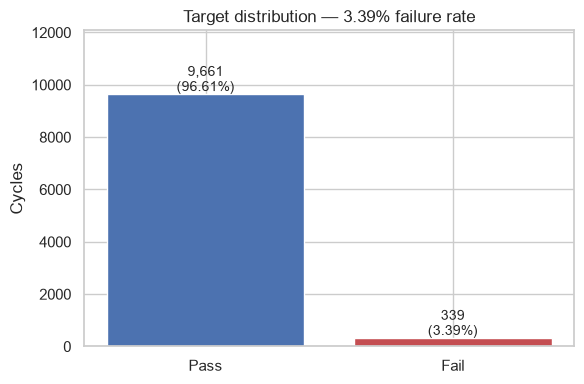

In [7]:
counts = df["Machine failure"].value_counts().rename(index={0: "Pass (no breakdown)", 1: "FAIL (breakdown)"})
display(counts.to_frame("cycles").assign(percent=lambda d: (d["cycles"] / len(df) * 100).round(2)))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Pass", "Fail"], [counts.iloc[0], counts.iloc[1]],
              color=["#4C72B0", "#C44E52"], edgecolor="white")
ax.set_title("Target distribution — 3.39% failure rate")
ax.set_ylabel("Cycles")
for bar, value in zip(bars, [counts.iloc[0], counts.iloc[1]]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100,
            "{:,}\n({:.2f}%)".format(value, value / len(df) * 100), ha="center", fontsize=10)
ax.set_ylim(0, counts.iloc[0] * 1.25)
plt.tight_layout()
plt.show()

### 4.5 Machine failure vs. the fault-type subtypes (EDA only)

The five subtype columns break the 339 failures down by cause. Overheating
(`HDF`) and over-strain (`OSF`) dominate. **These columns are never used as
model inputs** — see §2 and the leakage check in §6.

In [8]:
subtypes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
subtype_summary = pd.DataFrame({
    "failures": df[subtypes].sum(),
    "pct_of_all_rows": (df[subtypes].sum() / len(df) * 100).round(3),
})
display(subtype_summary)

# How many failures carry no subtype at all?
unlabelled = int(((df["Machine failure"] == 1) & df[subtypes].sum(axis=1) == 0).sum())
print(f"Failures with no subtype recorded: {unlabelled} "
      f"({unlabelled / df['Machine failure'].sum() * 100:.1f}% of all failures)")
print("-> the subtypes only partially restate the outcome, so they cannot be")
print("   used to reconstruct the label either.")

,failures,pct_of_all_rows
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19


Failures with no subtype recorded: 9693 (2859.3% of all failures)
-> the subtypes only partially restate the outcome, so they cannot be
   used to reconstruct the label either.


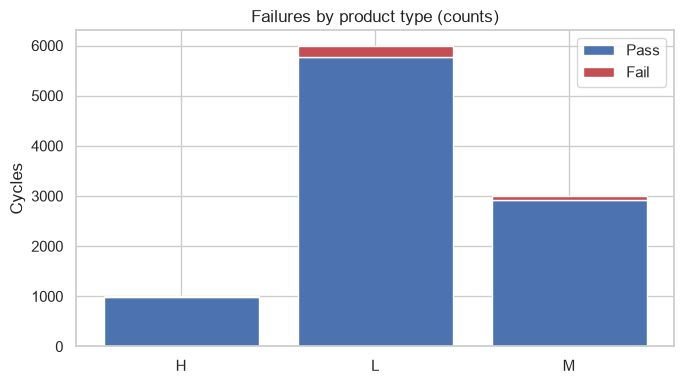

,failures,cycles,failure_rate
Type,,,
H,21,1003,2.09
L,235,6000,3.92
M,83,2997,2.77


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
left = df.groupby("Type")["Machine failure"].sum()
total = df.groupby("Type")["Machine failure"].count()
ax.bar(total.index, total - left, label="Pass", color="#4C72B0")
ax.bar(total.index, left, bottom=total - left, label="Fail", color="#C44E52")
ax.set_title("Failures by product type (counts)")
ax.set_ylabel("Cycles")
ax.legend()
plt.tight_layout()
plt.show()

display(
    df.groupby("Type")["Machine failure"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "failures", "count": "cycles", "mean": "failure_rate"})
    .assign(failure_rate=lambda d: (d["failure_rate"] * 100).round(2))
)

### 4.6 Distributions of the numeric features, split by the target

The failure mode is visible in the *relationship* between features rather than
in any single feature: failed cycles tend to show **high rotational speed with
low torque**, and **large process-minus-air temperature gaps**.

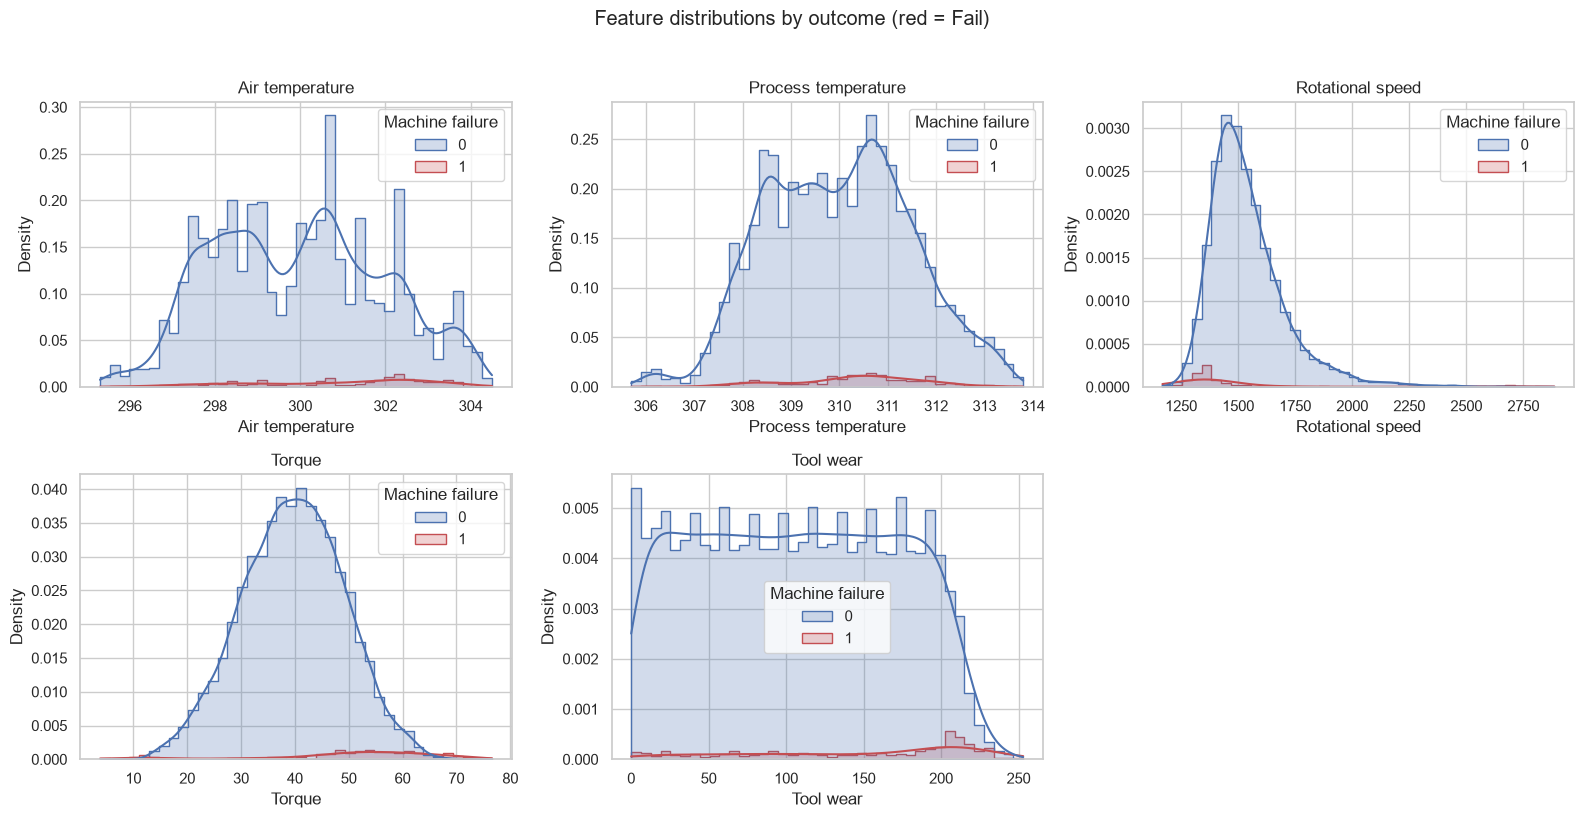

In [10]:
numeric_features = ["Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.ravel(), numeric_features):
    sns.histplot(data=df, x=feature, hue="Machine failure", kde=True, bins=40,
                 ax=ax, palette={0: "#4C72B0", 1: "#C44E52"}, element="step", stat="density")
    ax.set_title(feature)
axes.ravel()[-1].axis("off")
plt.suptitle("Feature distributions by outcome (red = Fail)", y=1.02)
plt.tight_layout()
plt.show()

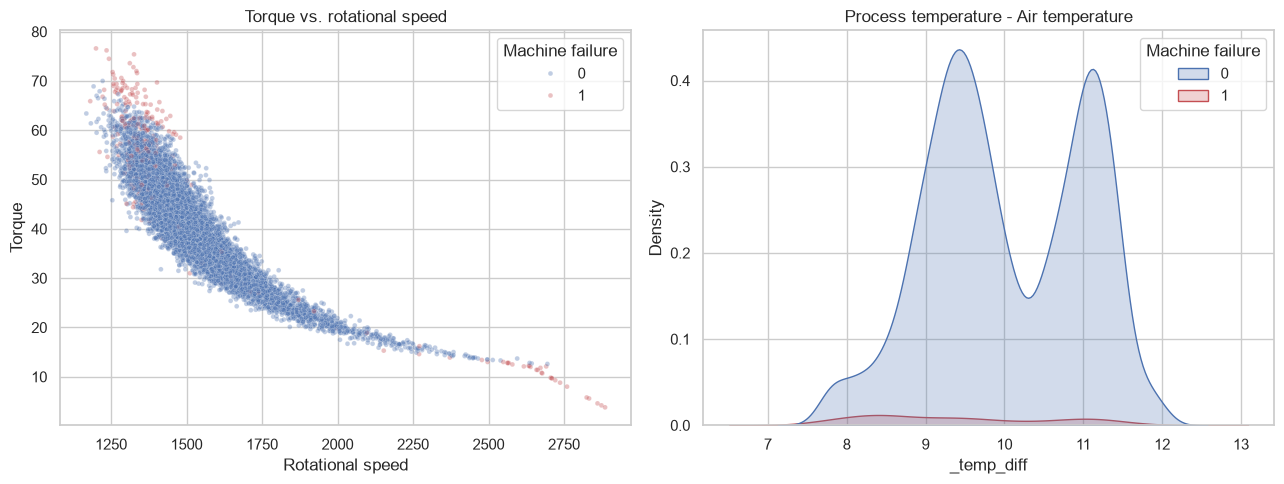

In [11]:
# The relationship the model actually exploits.
df["_temp_diff"] = df["Process temperature"] - df["Air temperature"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Rotational speed", y="Torque", hue="Machine failure",
                palette={0: "#4C72B0", 1: "#C44E52"}, alpha=0.35, ax=axes[0], s=12)
axes[0].set_title("Torque vs. rotational speed")
sns.kdeplot(data=df, x="_temp_diff", hue="Machine failure",
            fill=True, palette={0: "#4C72B0", 1: "#C44E52"}, ax=axes[1])
axes[1].set_title("Process temperature - Air temperature")
plt.tight_layout()
plt.show()

### 4.7 Correlation matrix

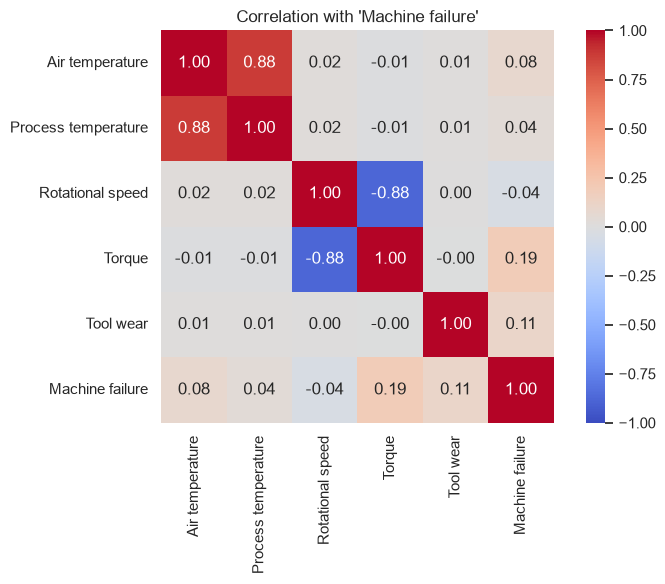

,corr with Machine failure
Air temperature,0.083
Process temperature,0.036
Rotational speed,-0.044
Torque,0.191
Tool wear,0.105
Machine failure,1.000


In [12]:
corr_cols = numeric_features + ["Machine failure"]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlation with 'Machine failure'")
plt.tight_layout()
plt.show()

display(corr["Machine failure"].round(3).to_frame("corr with Machine failure"))

### 4.8 Feature importance — an initial look

A quick random-forest importance ranking, before any tuning, gives a first
sense of which readings drive the outcome.

,importance
Rotational speed,0.3209
Torque,0.3173
Tool wear,0.2186
Air temperature,0.0873
Process temperature,0.0559


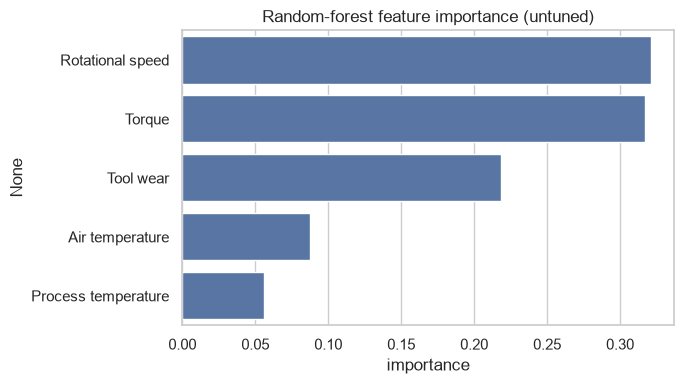

In [13]:
from sklearn.ensemble import RandomForestClassifier

quick = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               random_state=SEED, n_jobs=-1)
quick.fit(df[numeric_features], df["Machine failure"])
quick_imp = (
    pd.Series(quick.feature_importances_, index=numeric_features)
    .sort_values(ascending=False)
    .to_frame("importance")
)
display(quick_imp.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=quick_imp, x="importance", y=quick_imp.index, color="#4C72B0", ax=ax)
ax.set_title("Random-forest feature importance (untuned)")
plt.tight_layout()
plt.show()

## 5. Feature engineering (input side only)

All engineered features are **inputs**. None of them participates in building
the label.

### 5.1 Raw sensors and derived relationships

| Feature | Definition | Why |
|---|---|---|
| `air_temp` | Air temperature (K) | Ambient conditions |
| `proc_temp` | Process temperature (K) | Core process heat |
| `rot_speed` | Rotational speed (rpm) | Machine dynamics |
| `torque` | Torque (Nm) | Mechanical load |
| `tool_wear` | Tool wear | Tool degradation — a leading indicator |
| `temp_diff` | `proc_temp - air_temp` | Heat actually delivered to the workpiece, not just ambient temperature |
| `torque_per_krpm` | `torque / (rot_speed / 1000)` | Load per unit speed — flags a workpiece too heavy for the rpm |
| `wear_per_load` | `tool_wear / (torque + 1)` | Wear accumulated per unit of work done |
| `air_temp_oos` | `air_temp` outside 296–304 K | Out-of-spec operating flag |
| `proc_temp_oos` | `proc_temp` outside 307–313 K | Out-of-spec operating flag |
| `torque_oos` | `torque` outside 12–62 Nm | Out-of-spec operating flag |
| `rot_speed_oos` | `rot_speed` outside 1300–2200 rpm | Out-of-spec operating flag |
| `type_L`, `type_M` | One-hot of `Type` (H = reference) | Product quality tier |

**Dropped:** `UID` (row identifier), `Product ID` (type prefix + serial — pure
noise), and the five fault-subtype columns (leakage, §6).

### 5.2 Why the out-of-spec thresholds leak nothing

The thresholds are taken from the **univariate feature distributions** — the
bulk of the operating envelope — and were chosen **without reference to the
target**. §5.3 shows the resulting flag rates are a meaningful minority of
rows (1–4%), not 0% or 100%, which confirms they describe something real
rather than being fitted to the label.

In [14]:
# build_features() lives in src/data.py so that train.py and predict.py use
# exactly the same transformation. The notebook imports it -- it does not
# re-implement it.
X = build_features(df)
print("Feature matrix:", X.shape)
assert list(X.columns) == FEATURE_NAMES
X.head()

Feature matrix: (10000, 14)


,air_temp,proc_temp,rot_speed,torque,tool_wear,temp_diff,torque_per_krpm,wear_per_load,air_temp_oos,proc_temp_oos,torque_oos,rot_speed_oos,type_L,type_M
0,298.1,308.6,1551.0,42.8,0.0,10.5,27.595100,0.000000,0,0,0,0,0,1
1,298.2,308.7,1408.0,46.3,3.0,10.5,32.883523,0.063425,0,0,0,0,1,0
2,298.1,308.5,1498.0,49.4,5.0,10.4,32.977303,0.099206,0,0,0,0,1,0
3,298.2,308.6,1433.0,39.5,7.0,10.4,27.564550,0.172840,0,0,0,0,1,0
4,298.2,308.7,1408.0,40.0,9.0,10.5,28.409091,0.219512,0,0,0,0,1,0


,feature,low,high,observed_min,observed_max,flag_rate_%
0,air_temp,296.0,304.0,295.3,304.5,2.18
1,proc_temp,307.0,313.0,305.7,313.8,3.21
2,torque,12.0,62.0,3.8,76.6,1.47
3,rot_speed,1300.0,2200.0,1168.0,2886.0,3.07


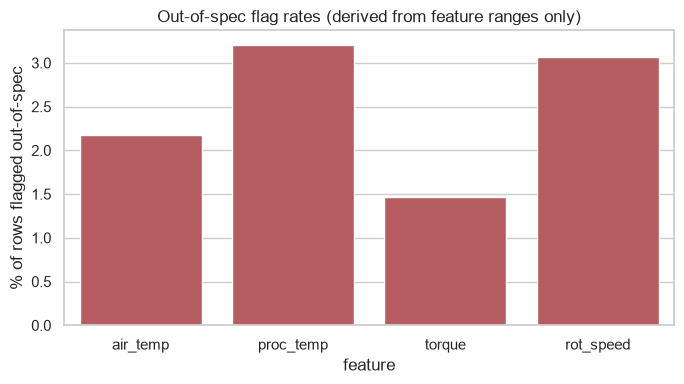

In [15]:
bounds = {
    "air_temp": ("Air temperature", 296.0, 304.0),
    "proc_temp": ("Process temperature", 307.0, 313.0),
    "torque": ("Torque", 12.0, 62.0),
    "rot_speed": ("Rotational speed", 1300.0, 2200.0),
}
rows = []
for feat, (col, low, high) in bounds.items():
    values = df[col]
    rows.append({
        "feature": feat,
        "low": low,
        "high": high,
        "observed_min": round(values.min(), 1),
        "observed_max": round(values.max(), 1),
        "flag_rate_%": round((X[f"{feat}_oos"].mean()) * 100, 2),
    })
bounds_table = pd.DataFrame(rows)
display(bounds_table)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=bounds_table, x="feature", y="flag_rate_%", color="#C44E52", ax=ax)
ax.set_ylabel("% of rows flagged out-of-spec")
ax.set_title("Out-of-spec flag rates (derived from feature ranges only)")
plt.tight_layout()
plt.show()

### 5.3 The derived label

`quality_fail` mirrors the manufacturer's ground-truth outcome from the
quality department's point of view: **1 = Fail, 0 = Pass**.

In [16]:
y = make_target(df)
print(f"Target 'quality_fail' (1 = FAIL): {int(y.sum()):,} failures of {len(y):,} rows ({y.mean() * 100:.2f}%)")
display(y.value_counts().rename(index={0: "Pass", 1: "Fail"}).to_frame("cycles"))

Target 'quality_fail' (1 = FAIL): 339 failures of 10,000 rows (3.39%)


,cycles
quality_fail,
Pass,9661
Fail,339


## 6. Leakage check — why `TWF/HDF/PWF/OSF/RNF` are excluded

This section measures, rather than asserts, the effect of the leakage we are
avoiding. A random forest is trained twice on the same split: once with the
honest feature set and once with the fault-subtype columns added.

The leaky model looks much better. That improvement is worthless — it comes
from a column that is recorded by the same inspection process that produces
the label, so it would not exist at prediction time in a real plant.

In [17]:
leaky_features = list(X.columns) + subtypes

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# The leaky frame = the honest engineered features PLUS the fault subtypes.
X_leaky = X.join(df[subtypes])
assert list(X_leaky.columns) == leaky_features

comparison = []
for label, train_frame, test_frame in [
    ("honest (no subtypes)", X_train, X_test),
    ("leaky (+ TWF/HDF/PWF/OSF/RNF)", X_leaky.loc[X_train.index], X_leaky.loc[X_test.index]),
]:
    model = RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    )
    model.fit(train_frame, y_train)
    prob = model.predict_proba(test_frame)[:, 1]
    comparison.append({
        "feature set": label,
        "n_features": train_frame.shape[1],
        "PR-AUC": round(average_precision_score(y_test, prob), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4),
    })

leakage_table = pd.DataFrame(comparison)
display(leakage_table)

gain = leakage_table.loc[1, "PR-AUC"] - leakage_table.loc[0, "PR-AUC"]
print(f"PR-AUC gain from the leaky columns: +{gain:.4f}")
print("-> That gain is the answer being read off the input. It would not")
print("   survive contact with real production data, so the subtypes are")
print("   excluded from the model and used only for the EDA in section 4.5.")

,feature set,n_features,PR-AUC,ROC-AUC
0,honest (no subtypes),14,0.8041,0.9605
1,leaky (+ TWF/HDF/PWF/OSF/RNF),19,0.9790,0.9901


PR-AUC gain from the leaky columns: +0.1749
-> That gain is the answer being read off the input. It would not
   survive contact with real production data, so the subtypes are
   excluded from the model and used only for the EDA in section 4.5.


## 7. Train / test split

Stratified 80/20. Stratification matters here: with only 339 positives, a
random split could leave too few failures in the test set for a stable PR-AUC.

In [18]:
print(f"Train: {len(X_train):,} rows | {int(y_train.sum())} Fail ({y_train.mean() * 100:.2f}%)")
print(f"Test : {len(X_test):,} rows | {int(y_test.sum())} Fail ({y_test.mean() * 100:.2f}%)")

Train: 8,000 rows | 271 Fail (3.39%)
Test : 2,000 rows | 68 Fail (3.40%)


## 8. Model selection and hyperparameter tuning

### 8.1 Candidates

| Model | Family | Why included |
|---|---|---|
| `LogisticRegression` | linear | Interpretable baseline; coefficient signs are meaningful |
| `RandomForestClassifier` | tree ensemble | Strong baseline, captures interactions, gives importances |
| `HistGradientBoostingClassifier` | boosting | Typically the strongest on tabular data |

All three run inside a `Pipeline`, so preprocessing is refitted **within every
CV fold** and no information leaks from the validation folds.

### 8.2 Handling the imbalance — and why not SMOTE

`class_weight="balanced"` is applied to every classifier. It re-weights the
339 positive examples by roughly 28× during fitting.

SMOTE / `imblearn` is deliberately **not** used: with only 339 positive rows,
synthetic oversampling can generate near-duplicate positives that then land in
the validation fold, producing optimistically biased CV scores.
`class_weight` addresses the imbalance without fabricating data.

**Scoring:** `average_precision` (PR-AUC). It is threshold-free, correct at
3.4% prevalence, and far more stable across folds than a threshold-dependent
metric such as F2 — the decision threshold is tuned separately in §8.3.

In [19]:
pipelines = get_pipelines()
grids = get_grids()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for name, pipeline in pipelines.items():
    print(f"{name}:")
    print(f"  steps : {[step for step, _ in pipeline.steps]}")
    print(f"  grid  : {grids[name]}")

logreg:
  steps : ['scale', 'clf']
  grid  : {'clf__C': [0.01, 0.1, 1.0, 10.0, 100.0], 'clf__solver': ['liblinear', 'lbfgs']}
rf:
  steps : ['clf']
  grid  : {'clf__n_estimators': [200, 500], 'clf__max_depth': [None, 8, 15], 'clf__min_samples_leaf': [1, 3, 5], 'clf__max_features': ['sqrt', 0.5], 'clf__class_weight': ['balanced', 'balanced_subsample']}
hgb:
  steps : ['clf']
  grid  : {'clf__max_iter': [200, 400], 'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__max_leaf_nodes': [15, 31, 63], 'clf__min_samples_leaf': [10, 20, 40], 'clf__l2_regularization': [0.0, 1.0]}


### 8.3 Grid search

In [20]:
search_results = []
fitted = {}

for name, pipeline in pipelines.items():
    print(f"\n--- GridSearchCV: {name} ---")
    search = GridSearchCV(
        pipeline, grids[name], scoring="average_precision", cv=cv, n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    print(f"best params : {search.best_params_}")
    print(f"CV PR-AUC   : {search.best_score_:.4f}")

    best_pipeline = search.best_estimator_
    fitted[name] = best_pipeline

    # Threshold tuned on OUT-OF-FOLD training predictions only, so the
    # threshold is never chosen on data the model was fitted on.
    oof = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    threshold = tune_threshold(y_train, oof)

    test_prob = best_pipeline.predict_proba(X_test)[:, 1]
    test_metrics = evaluate(y_test, test_prob, threshold)

    search_results.append({
        "model": name,
        "cv_pr_auc": round(search.best_score_, 4),
        "threshold": round(threshold, 3),
        "roc_auc": round(test_metrics["roc_auc"], 4),
        "recall": round(test_metrics["recall"], 4),
        "precision": round(test_metrics["precision"], 4),
        "f2": round(test_metrics["f2"], 4),
        "best_params": search.best_params_,
    })

results = pd.DataFrame(search_results).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
display(results[["model", "cv_pr_auc", "threshold", "roc_auc", "recall", "precision", "f2"]])


--- GridSearchCV: logreg ---


best params : {'clf__C': 1.0, 'clf__solver': 'liblinear'}
CV PR-AUC   : 0.4760



--- GridSearchCV: rf ---


best params : {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 500}
CV PR-AUC   : 0.8255



--- GridSearchCV: hgb ---


best params : {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.2, 'clf__max_iter': 200, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 10}
CV PR-AUC   : 0.8445


,model,cv_pr_auc,threshold,roc_auc,recall,precision,f2
0,hgb,0.8445,0.41,0.9850,0.8971,0.6162,0.8221
1,rf,0.8255,0.36,0.9808,0.8382,0.7500,0.8190
2,logreg,0.4760,0.77,0.9392,0.7206,0.3603,0.6005


In [21]:
for row in results.itertuples():
    print(f"{row.model}:")
    for key, value in row.best_params.items():
        print(f"    {key} = {value}")

hgb:
    clf__l2_regularization = 1.0
    clf__learning_rate = 0.2
    clf__max_iter = 200
    clf__max_leaf_nodes = 31
    clf__min_samples_leaf = 10
rf:
    clf__class_weight = balanced_subsample
    clf__max_depth = None
    clf__max_features = 0.5
    clf__min_samples_leaf = 3
    clf__n_estimators = 500
logreg:
    clf__C = 1.0
    clf__solver = liblinear


### 8.4 Model comparison

The winner is chosen by **cross-validated PR-AUC** on the training split, not
by test performance — the test set is touched only once, at the end.

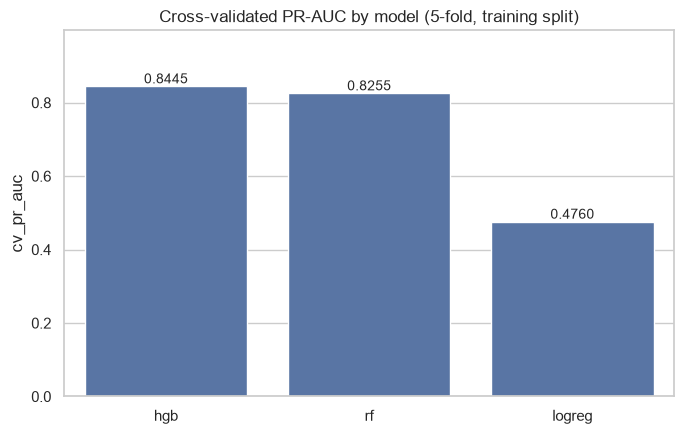

Selected model: hgb  (threshold = 0.41)


In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=results, x="model", y="cv_pr_auc", color="#4C72B0", ax=ax)
for i, row in results.iterrows():
    ax.text(i, row["cv_pr_auc"] + 0.008, f"{row['cv_pr_auc']:.4f}", ha="center", fontsize=10)
ax.set_ylim(0, results["cv_pr_auc"].max() * 1.18)
ax.set_xlabel("")
ax.set_title("Cross-validated PR-AUC by model (5-fold, training split)")
plt.tight_layout()
plt.show()

best_name = results.iloc[0]["model"]
best_pipeline = fitted[best_name]
best_threshold = float(results.iloc[0]["threshold"])
print(f"Selected model: {best_name}  (threshold = {best_threshold})")

### 8.5 Threshold tuning

The model's default 0.5 cut-off is not the operating point we want. The
threshold is swept over out-of-fold predictions and the one maximising **F2**
is chosen.

F2 weights recall four times as heavily as precision. That is the right
trade-off for a screening tool: a false positive costs one extra inspection,
a false negative ships a defective product.

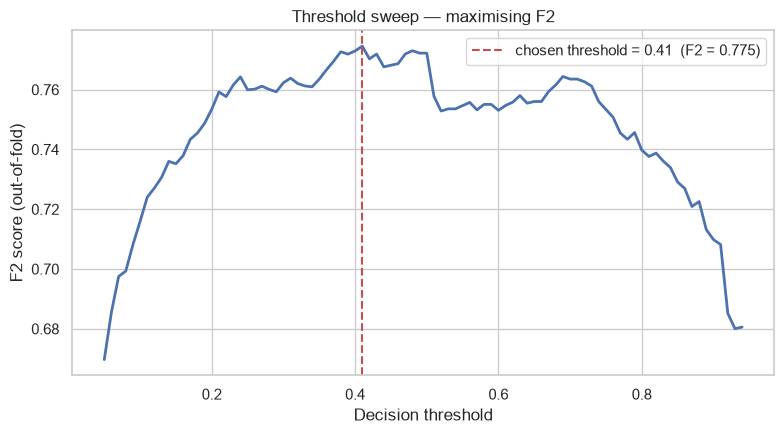

In [23]:
oof = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.arange(0.05, 0.95, 0.01)
f2_scores = [f2_score(y_train, (oof >= t).astype(int)) for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, f2_scores, color="#4C72B0", linewidth=2)
ax.axvline(best_threshold, color="#C44E52", linestyle="--",
            label=f"chosen threshold = {best_threshold:.2f}  (F2 = {max(f2_scores):.3f})")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("F2 score (out-of-fold)")
ax.set_title("Threshold sweep — maximising F2")
ax.legend()
plt.tight_layout()
plt.show()

### 8.6 Final model on the held-out test set

In [24]:
best_pipeline.fit(X_train, y_train)
test_prob = best_pipeline.predict_proba(X_test)[:, 1]
metrics = evaluate(y_test, test_prob, best_threshold)

print(f"=== Final model: {best_name} (threshold = {best_threshold}) ===")
for key in ["pr_auc", "roc_auc", "recall", "precision", "f2", "accuracy"]:
    print(f"  {key:<10} {metrics[key]:.4f}")
print(f"  confusion  {metrics['confusion_matrix']}")

# Context: what does the trivial baseline achieve?
baseline = evaluate(y_test, np.zeros(len(y_test)), 0.5)
print(f"\nAlways-'Pass' baseline: PR-AUC = {baseline['pr_auc']:.4f}, "
      f"accuracy = {baseline['accuracy']:.4f}, recall = {baseline['recall']:.4f}")
print("-> 96.6% accuracy while catching no failures at all: accuracy is not")
print("   a meaningful metric for this task.")

=== Final model: hgb (threshold = 0.41) ===
  pr_auc     0.8966
  roc_auc    0.9850
  recall     0.8971
  precision  0.6162
  f2         0.8221
  accuracy   0.9775
  confusion  {'tn': 1894, 'fp': 38, 'fn': 7, 'tp': 61}

Always-'Pass' baseline: PR-AUC = 0.0340, accuracy = 0.9660, recall = 0.0000
-> 96.6% accuracy while catching no failures at all: accuracy is not
   a meaningful metric for this task.


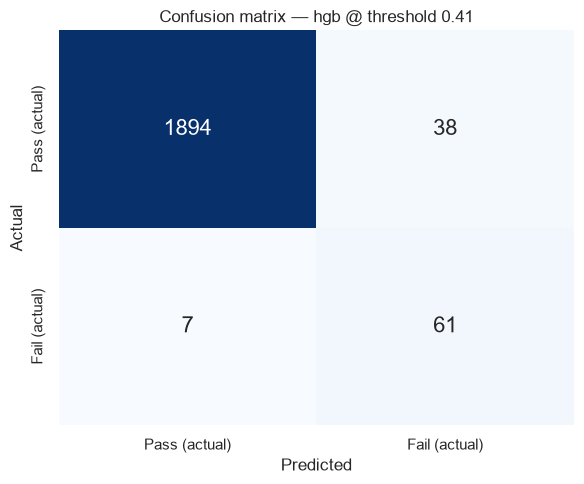

In [25]:
tn, fp, fn, tp = (metrics["confusion_matrix"][k] for k in ("tn", "fp", "fn", "tp"))
cm = np.array([[tn, fp], [fn, tp]])
labels = ["Pass (actual)", "Fail (actual)"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=labels, yticklabels=labels,
            annot_kws={"size": 16})
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix — {best_name} @ threshold {best_threshold}")
plt.tight_layout()
plt.show()

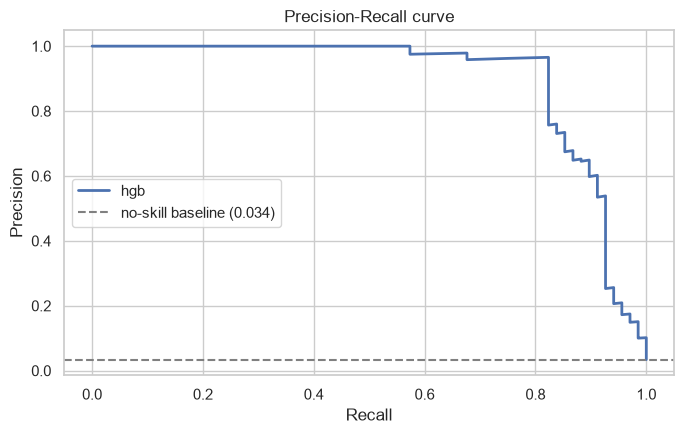

In [26]:
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_prob)
baseline_rate = float(y_test.mean())

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(recall_curve, precision_curve, color="#4C72B0", linewidth=2, label=best_name)
ax.axhline(baseline_rate, color="grey", linestyle="--", label=f"no-skill baseline ({baseline_rate:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve")
ax.legend()
plt.tight_layout()
plt.show()

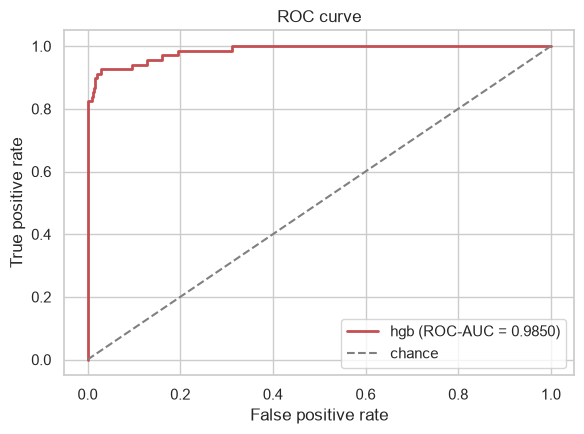

In [27]:
fpr, tpr, _ = roc_curve(y_test, test_prob)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(fpr, tpr, color="#C44E52", linewidth=2,
        label=f"{best_name} (ROC-AUC = {metrics['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Feature importance

Permutation importance on the test set: it measures how much the model's
score degrades when a single feature is shuffled, and it works for any
estimator (unlike `.feature_importances_`, which is unavailable on a
`Pipeline`).

,feature,importance_mean,importance_std
0,temp_diff,0.50143,0.05070
1,rot_speed,0.48067,0.04890
2,torque,0.25055,0.01513
3,tool_wear,0.21607,0.01942
4,torque_per_krpm,0.19724,0.02955
5,wear_per_load,0.02554,0.00761
6,type_L,0.01258,0.00627
7,proc_temp,0.00748,0.00238
8,air_temp,0.00216,0.00440
9,type_M,0.00216,0.00275


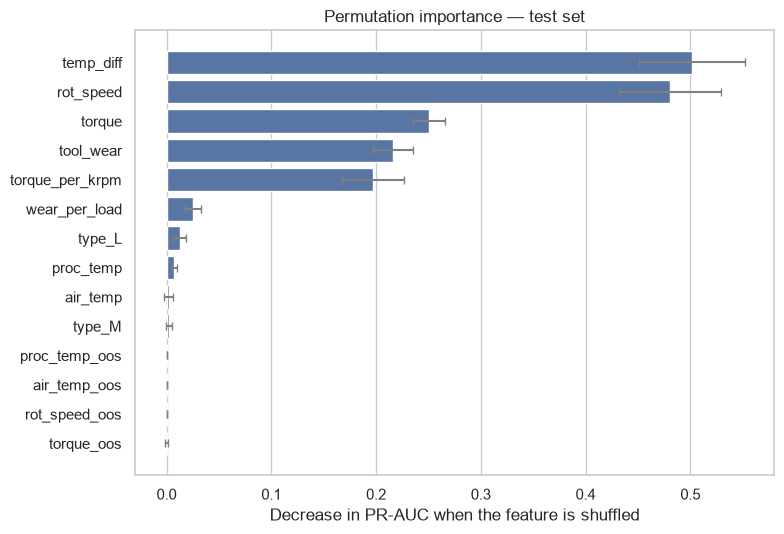

In [28]:
perm = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=10, random_state=SEED,
    scoring="average_precision", n_jobs=-1,
)
importance = (
    pd.DataFrame({
        "feature": list(X_test.columns),
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(importance.round(5))

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(data=importance, x="importance_mean", y="feature", color="#4C72B0", ax=ax)
ax.errorbar(importance["importance_mean"], importance["feature"],
            xerr=importance["importance_std"], fmt="none", ecolor="grey", capsize=3)
ax.set_xlabel("Decrease in PR-AUC when the feature is shuffled")
ax.set_ylabel("")
ax.set_title("Permutation importance — test set")
plt.tight_layout()
plt.show()

### 9.1 The linear model's view

The tuned logistic regression is interpretable: its coefficients show the
*direction* of each effect. These signs agree with the permutation
importance above — a large temperature gap and a high torque-per-speed ratio
push the model toward a failure verdict.

,coefficient
torque_per_krpm,7.1299
rot_speed,1.9195
wear_per_load,0.6657
tool_wear,0.5722
air_temp,0.2684
torque_oos,0.2533
type_L,0.1832
proc_temp_oos,0.0248
type_M,-0.0321
air_temp_oos,-0.0442


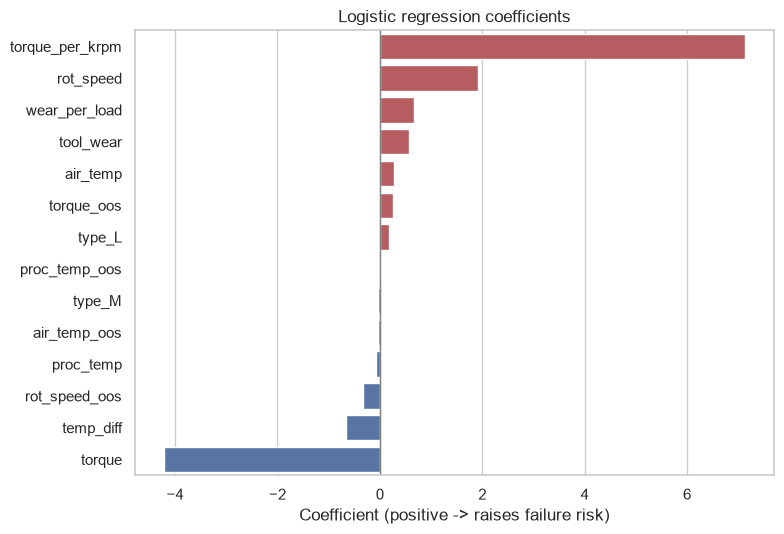

Reading: positive coefficients push the model toward FAIL.
  temp_diff      -> a large process-minus-air gap raises failure risk
  torque_per_krpm -> heavy load at low speed raises failure risk
  wear_per_load  -> a worn tool under light load raises failure risk


In [29]:
logreg_pipeline = fitted["logreg"]
coefficients = (
    pd.Series(logreg_pipeline.named_steps["clf"].coef_[0], index=FEATURE_NAMES)
    .sort_values(ascending=False)
    .to_frame("coefficient")
)
display(coefficients.round(4))

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in coefficients["coefficient"]]
sns.barplot(data=coefficients, x="coefficient", y=coefficients.index, palette=colors, ax=ax)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Coefficient (positive -> raises failure risk)")
ax.set_ylabel("")
ax.set_title("Logistic regression coefficients")
plt.tight_layout()
plt.show()

print("Reading: positive coefficients push the model toward FAIL.")
print("  temp_diff      -> a large process-minus-air gap raises failure risk")
print("  torque_per_krpm -> heavy load at low speed raises failure risk")
print("  wear_per_load  -> a worn tool under light load raises failure risk")

## 10. Results summary

In [30]:
summary = pd.DataFrame({
    "model": ["Always 'Pass' (baseline)"] + results["model"].tolist(),
    "PR-AUC": [round(baseline["pr_auc"], 4)] + results["cv_pr_auc"].tolist(),
    "ROC-AUC": [round(baseline["roc_auc"], 4)] + results["roc_auc"].tolist(),
    "Recall": [round(baseline["recall"], 4)] + results["recall"].tolist(),
    "Precision": [round(baseline["precision"], 4)] + results["precision"].tolist(),
    "F2": [round(baseline["f2"], 4)] + results["f2"].tolist(),
    "Accuracy": [round(baseline["accuracy"], 4)]
    + [round(evaluate(y_test, fitted[m].predict_proba(X_test)[:, 1], float(results.loc[results["model"] == m, "threshold"].iloc[0]))["accuracy"], 4) for m in results["model"]],
})
display(summary)
print("PR-AUC / ROC-AUC / Recall / Precision / F2 are measured on the held-out")
print("test set at each model's own tuned threshold. Accuracy is included for")
print("completeness only -- it is misleading at 3.39% prevalence.")

,model,PR-AUC,ROC-AUC,Recall,Precision,F2,Accuracy
0,Always 'Pass' (baseline),0.0340,0.5000,0.0000,0.0000,0.0000,0.9660
1,hgb,0.8445,0.9850,0.8971,0.6162,0.8221,0.9775
2,rf,0.8255,0.9808,0.8382,0.7500,0.8190,0.9850
3,logreg,0.4760,0.9392,0.7206,0.3603,0.6005,0.9470


PR-AUC / ROC-AUC / Recall / Precision / F2 are measured on the held-out
test set at each model's own tuned threshold. Accuracy is included for
completeness only -- it is misleading at 3.39% prevalence.


In [31]:
print(f"Selected model : {best_name}")
print(f"Threshold      : {best_threshold}")
print(f"Test PR-AUC    : {metrics['pr_auc']:.4f}")
print(f"Test ROC-AUC   : {metrics['roc_auc']:.4f}")
print(f"Recall         : {metrics['recall']:.4f}")
print(f"Precision      : {metrics['precision']:.4f}")
print(f"F2             : {metrics['f2']:.4f}")
print(f"Confusion      : {metrics['confusion_matrix']}")
print()
print("Reading the confusion matrix:")
print(f"  {tp} of {tp + fn} real failures were caught (recall {metrics['recall']:.1%}).")
print(f"  {fp} good products were flagged for extra inspection (false alarms).")
print(f"  {fn} real failures slipped through -- these are the ones that ship.")

Selected model : hgb
Threshold      : 0.41
Test PR-AUC    : 0.8966
Test ROC-AUC   : 0.9850
Recall         : 0.8971
Precision      : 0.6162
F2             : 0.8221
Confusion      : {'tn': 1894, 'fp': 38, 'fn': 7, 'tp': 61}

Reading the confusion matrix:
  61 of 68 real failures were caught (recall 89.7%).
  38 good products were flagged for extra inspection (false alarms).
  7 real failures slipped through -- these are the ones that ship.


## 11. Limitations and future work

- **Only 339 failures.** The metric estimates carry real variance; the
  stratified 5-fold CV and the fixed seed keep the comparison reproducible,
  but a single PR-AUC figure should not be over-read.
- **The label is the breakdown label.** AI4I has no independent
  human-inspection quality column, so `quality_fail` is derived from
  `Machine failure` (§2). A plant with real inspection verdicts would
  retrain on those instead — the pipeline is unchanged.
- **The fault subtypes are unavailable at prediction time** in the real
  world, which is exactly why they are excluded (§6).
- **No time dimension.** Rows are independent production cycles; the model
  does not model drift or the tool-wear trajectory over time. A sequential
  model (or adding a rolling tool-wear feature) would be the natural next step.
- **Threshold drift.** The decision threshold was tuned on this dataset's
  operating envelope; it should be re-tuned as the plant changes.
- **Real failure rates are higher than 3.4%.** On a line with a 20% failure
  rate the same classifier would need different thresholds and would look
  considerably better than these numbers.

## 12. Reproducibility

- `SEED = 42` is fixed everywhere (split, CV, models, permutation importance).
- Package versions are pinned in `requirements.txt`.
- The dataset is committed at `data/raw/ai4i2020.csv` — no network needed.
- The notebook's training logic is mirrored exactly by `train.py`, which
  regenerates `artifacts/model.joblib` and `artifacts/metrics.json`.

The cell below saves the same artifact the training script produces.

In [32]:
out_dir = Path("artifacts")
out_dir.mkdir(exist_ok=True)

artifact = {
    "pipeline": best_pipeline,
    "threshold": best_threshold,
    "feature_names": list(FEATURE_NAMES),
    "metrics": metrics,
    "results": results.drop(columns=["best_params"]).to_dict(orient="records"),
    "importance": importance.to_dict(orient="records"),
    "target_definition": "quality_fail = 'Machine failure'  (1 = FAIL, 0 = Pass)",
    "model_name": best_name,
    "trained_at": datetime.now(timezone.utc).isoformat(),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, out_dir / "model.joblib")
print(f"Saved {out_dir / 'model.joblib'}")

Saved artifacts\model.joblib


### 12.1 Consistency guard

The notebook, `train.py` and `predict.py` must agree on the feature columns.
This check asserts that the feature matrix built here matches the shared
definition in `src/data.py` exactly — the guard that keeps serving correct.

In [33]:
from src.data import DEFAULT_DATA_PATH, TARGET_COL, TARGET_DEFINITION

assert list(X.columns) == FEATURE_NAMES, "Notebook feature list drifted from src/data.py"
assert len(FEATURE_NAMES) == 14 and len(set(FEATURE_NAMES)) == 14
assert not set(subtypes) & set(FEATURE_NAMES), "Leaky fault subtypes present in the feature set"
assert TARGET_COL == "quality_fail" and y.name == TARGET_COL
assert int(y.sum()) == int(df["Machine failure"].sum()), "Label is not the ground-truth breakdown"

print("OK  feature list matches src/data.py")
print("OK  no fault-subtype columns in the feature set")
print("OK  label is derived from the ground-truth 'Machine failure' column")
print("OK  dataset path:", DEFAULT_DATA_PATH)
print("OK  target definition:", TARGET_DEFINITION)

OK  feature list matches src/data.py
OK  no fault-subtype columns in the feature set
OK  label is derived from the ground-truth 'Machine failure' column
OK  dataset path: data\raw\ai4i2020.csv
OK  target definition: quality_fail = 'Machine failure'  (1 = FAIL quality inspection, 0 = Pass). Ground truth 'Machine failure' is the manufacturer's own breakdown label; the quality verdict is derived from it as quality_pass = 1 - quality_fail.
